# SPY buy and hold: engine check

**Author:** Franz Triebe · **Date:** 2026-10-11 · **Status:** final

**Question.** Does the new `quantlab` engine reproduce two well known facts about holding SPY since 1993: a volatility of about 19% a year and a maximum drawdown of about 55% in 2007 to 2009? If it does, we can trust it with the strategies in the next phases.

**Data.** SPY daily adjusted closes from Yahoo Finance (dividends reinvested), February 1993 to October 2026, retrieved 2026-10-11. Daily one month T bill rate from the Ken French data library, available until 2026-08-31.

> **Key findings**
> 1. Volatility is **18.5% a year** and the maximum drawdown is **55.2%** (9 Oct 2007 to 9 Mar 2009). Both match the expected values, so the engine passes the Phase 1 check.
> 2. Over 33.7 years SPY earned **9.6% a year above cash** (10.9% a year in total), a Sharpe ratio of **0.52**. One dollar grew to about 32 dollars.
> 3. Daily returns are far from normal: kurtosis is **14.9** (a normal distribution has 3) and volatility ranged from 5% to 74% a year. The referee in Phase 2 has to account for both.

**Contents**
1. [Setup](#1.-Setup)
2. [Data](#2.-Data)
3. [Method](#3.-Method)
4. [Results](#4.-Results)
5. [Conclusions](#5.-Conclusions)
6. [Appendix: environment](#6.-Appendix:-environment)

## 1. Setup

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quantlab
from IPython.display import display
from quantlab import acad, backtest, data, plotting, risk, stats

In [2]:
TICKER = "SPY"  # Yahoo symbol; SPY is a total return series via adjusted closes
START = "1993-01-01"  # first date to keep (SPY starts on 1993-01-29)
LAG = 1  # trading days between a decision at the close and the first return it earns
COST_BPS = 5.0  # cost per unit of one way turnover, in basis points
ANN_FACTOR = 252  # trading days per year, for annualizing
VOL_WINDOW = 63  # rolling volatility window in trading days (about 3 months)
REFRESH = False  # True downloads fresh data instead of using the cache in data/
OUTPUT_DIR = Path(quantlab.__file__).resolve().parents[1] / "output" / "p01"

In [3]:
acad.apply_style()
pd.options.display.float_format = "{:,.4f}".format
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Data

We load **daily simple returns** $r_t = P_t/P_{t-1}-1$ from adjusted closes. Adjusted closes fold dividends back into the price, so for SPY these are total returns. Both downloads are cached in `data/`, so rerunning this notebook gives exactly the same numbers.

> **Assumption:** the Ken French library publishes the risk free rate with a lag of one to two months. For the most recent days we carry the last published rate forward. T bill rates barely move within a month, so the effect on excess returns is negligible.

In [4]:
returns = data.load_yahoo(TICKER, start=START, refresh=REFRESH)
rf_published = data.load_rf_daily(refresh=REFRESH)
rf = rf_published.reindex(returns.index).ffill()
n_filled = int((returns.index > rf_published.index[-1]).sum())

assert isinstance(returns.index, pd.DatetimeIndex)
assert returns.index.is_monotonic_increasing and returns.index.is_unique
assert not returns.isna().any() and not rf.isna().any()
print(
    f"{len(returns):,} daily returns from {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}"
)
print(
    f"Risk free rate published until {rf_published.index[-1]:%Y-%m-%d}; carried forward for {n_filled} days"
)

8,481 daily returns from 1993-02-01 to 2026-10-09
Risk free rate published until 2026-08-31; carried forward for 28 days


In [5]:
data_overview = (
    pd.DataFrame({"SPY return": returns, "risk free rate": rf}).describe().drop("count")
)
display(data_overview.style.format("{:.4%}"))
print(
    f"Worst day {returns.idxmin():%Y-%m-%d} ({returns.min():.1%}), best day {returns.idxmax():%Y-%m-%d} ({returns.max():.1%})"
)
print(f"Autocorrelation of daily returns at lag 1: {returns.autocorr():.3f}")

,SPY return,risk free rate
mean,0.0478%,0.0097%
std,1.1668%,0.0088%
min,-10.9424%,0.0000%
25%,-0.4319%,0.0000%
50%,0.0681%,0.0100%
75%,0.5947%,0.0200%
max,14.5197%,0.0300%


Worst day 2020-03-16 (-10.9%), best day 2008-10-13 (14.5%)
Autocorrelation of daily returns at lag 1: -0.082


**Reading the table.** The average day earns about 0.05% and the risk free rate about 0.01%. Daily returns are slightly negatively autocorrelated ($-0.08$ at lag 1): a strong day tends to be followed by a small reversal. The worst day was about $-11\%$ (March 2020) and the best about $+15\%$ (October 2008).

> **Caveat:** the Ken French file rounds the daily rate to 0.01%, so each day is 0.00%, 0.01% or 0.02%. Single days are imprecise, but the long run average (about 2.5% a year) is right, and that is what matters for the statistics below.

## 3. Method

Buy and hold means a target weight of $w_t = 1$ on every day. `backtest.run` turns weights into returns, and it is the only place in the repo that applies the lag:

$$\text{position}_t = w_{t-1}, \qquad x_t = \text{position}_t \,(r_t-r^f_t)-\text{cost}_t, \qquad \text{total}_t = x_t + r^f_t$$

where $x_t$ is the **excess return** (return above cash), $r^f_t$ the daily risk free rate, and $\text{cost}_t = |\text{position}_t-\text{position}_{t-1}| \times 5\text{ bp}$. For buy and hold the only trade is entering the market on the first day.

The statistics in Section 4 use $x_t$: annualized mean $= 252\,\bar x$, annualized volatility $= \sqrt{252}\,s_x$, Sharpe ratio $=$ their ratio. Drawdowns use total returns, because that is what an investor sees in the account.

In [6]:
weights = pd.Series(1.0, index=returns.index, name="weight")
result = backtest.run(weights, returns, lag=LAG, cost_bps=COST_BPS, rf=rf).dropna()

assert len(result) == len(returns) - LAG
assert (result["position"] == 1).all()
assert result["cost"].sum() == COST_BPS / 10_000  # one entry trade, nothing after

### 3.1 What does a weight set on Monday earn?

The first rows make the lag visible. The weight decided at the close of 1 February 1993 (a Monday) becomes the position held on Tuesday 2 February, and earns Tuesday's return. Monday's own return is not earned, because at Monday's close it was already over.

In [7]:
first_days = pd.DataFrame(
    {
        "weight set at close": weights,
        "return that day": returns,
        "position held": result["position"],
        "excess return earned": result["excess"],
    }
).iloc[:4]
first_days.index = first_days.index.strftime("%a %Y-%m-%d")
display(
    first_days.style.format(
        {
            "weight set at close": "{:.0f}",
            "position held": "{:.0f}",
            "return that day": "{:.4%}",
            "excess return earned": "{:.4%}",
        },
        na_rep="none yet",
    )
)

,weight set at close,return that day,position held,excess return earned
date,,,,
Mon 1993-02-01,1,0.7112%,none yet,none yet
Tue 1993-02-02,1,0.2119%,1,0.1519%
Wed 1993-02-03,1,1.0571%,1,1.0471%
Thu 1993-02-04,1,0.4184%,1,0.4084%


**Reading the table.** On 2 February the excess return is the SPY return minus the risk free rate minus the 5 bp entry cost. From then on there are no costs, because the position never changes.

## 4. Results

### 4.1 Summary statistics

The two numbers this notebook checks are **annualized volatility** (expected about 19%) and **maximum drawdown** (expected about $-55\%$). We also report the t statistic of the mean excess return, once with the textbook iid standard error and once with Newey West (HAC) standard errors that allow for autocorrelation and changing volatility.

In [8]:
summary = stats.summary(
    result["excess"], total=result["total"], position=result["position"]
)
summary["t_stat_iid"] = stats.tstat_mean(result["excess"])
summary["t_stat_newey_west_5"] = stats.tstat_mean(result["excess"], nw_lags=5)
summary["years"] = len(result) / ANN_FACTOR

percent_rows = [
    "ann_mean_excess",
    "ann_geo_total",
    "ann_vol",
    "max_drawdown",
    "hit_rate",
    "time_in_market",
]
summary_table = summary.to_frame("SPY buy and hold")
display(
    summary_table.style.format(lambda v: f"{v:.2f}").format(
        "{:.1%}", subset=pd.IndexSlice[percent_rows, :]
    )
)

,SPY buy and hold
ann_mean_excess,9.6%
ann_geo_total,10.9%
ann_vol,18.5%
sharpe,0.52
sortino,0.73
max_drawdown,-55.2%
calmar,0.20
skew,-0.01
kurtosis,14.86
hit_rate,53.8%


In [9]:
total_drawdown = risk.drawdown(result["total"])
trough = total_drawdown.idxmin()
wealth = (1 + result["total"]).cumprod()
peak = wealth.loc[:trough].idxmax()
recovered = wealth.loc[trough:][wealth.loc[trough:] >= wealth.loc[peak]].index[0]
print(f"Volatility {summary['ann_vol']:.1%} a year (check: about 19%)")
print(
    f"Max drawdown {summary['max_drawdown']:.1%}: peak {peak:%Y-%m-%d}, trough {trough:%Y-%m-%d}, back at the peak {recovered:%Y-%m-%d}"
)
assert 0.17 < summary["ann_vol"] < 0.21 and -0.60 < summary["max_drawdown"] < -0.50

Volatility 18.5% a year (check: about 19%)
Max drawdown -55.2%: peak 2007-10-09, trough 2009-03-09, back at the peak 2012-08-16


**Reading the table.** Both checks pass: volatility is 18.5% a year and the maximum drawdown is 55.2%, from the October 2007 peak to the March 2009 trough. It took until August 2012 to get back to the old peak. The Sharpe ratio of 0.52 is typical for US equities over long periods.

Two numbers matter for the next phases. **Kurtosis is about 15**, five times the normal value of 3: extreme days happen far more often than a normal distribution predicts, which makes Sharpe ratios less precise than the textbook formula says. And the **Newey West t statistic (3.3) differs from the iid one (3.0)**, because daily index returns are slightly negatively autocorrelated. Both effects are built into the referee in Phase 2.

### 4.2 Growth of one dollar and drawdowns

Panel (a) shows wealth on a log scale, where equal vertical distances mean equal percentage changes. Panel (b) shows how far wealth was below its previous peak on each day. Grey bands are US recessions (NBER).

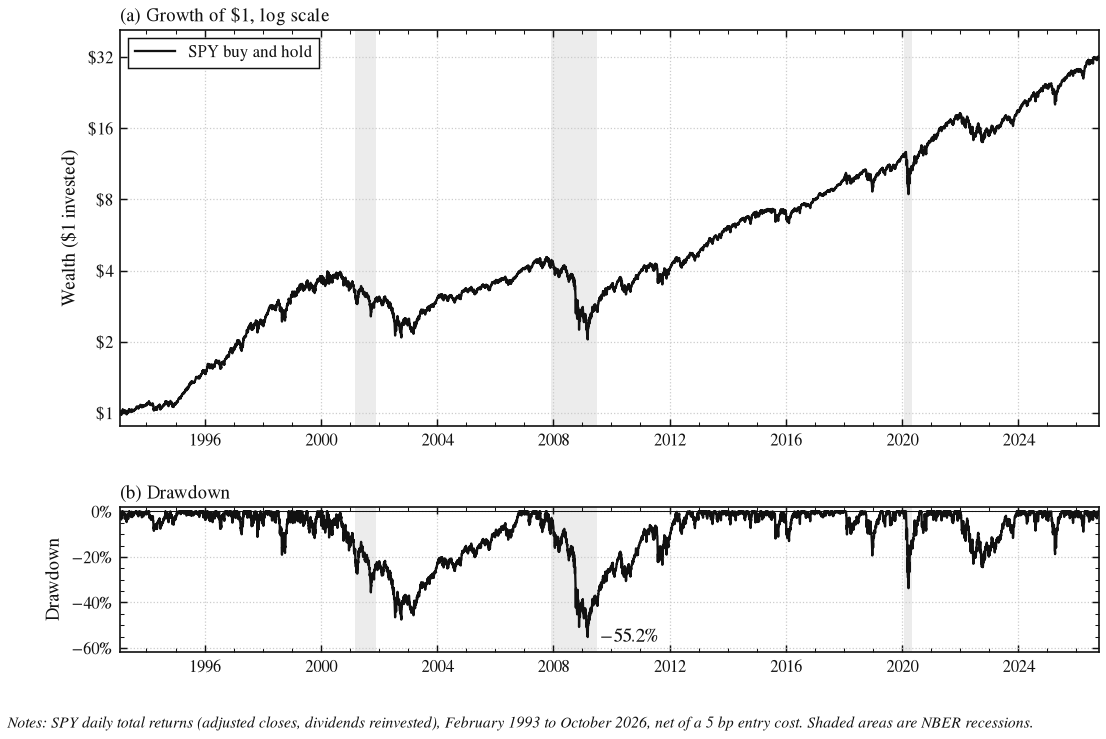

In [10]:
fig, (ax_w, ax_dd) = acad.wealth_drawdown_figure(
    {"SPY buy and hold": result["total"]},
    table=False,
    note="Notes: SPY daily total returns (adjusted closes, dividends reinvested), February 1993 to October 2026, net of a 5 bp entry cost. Shaded areas are NBER recessions.",
)
ax_dd.annotate(
    f"{total_drawdown.min():.1%}".replace("-", "−"),
    (trough, total_drawdown.min()),
    xytext=(6, 0),
    textcoords="offset points",
    va="center",
)
acad.save(fig, "f0_spy_buy_and_hold", outdir=OUTPUT_DIR)
plt.show()

**Figure 1.** SPY turned one dollar into about 32 dollars between 1993 and 2026, but lost 55% from October 2007 to March 2009.

**Reading the chart.** Three large drawdowns stand out: the dot com crash ($-47.5\%$ from March 2000 to October 2002), the financial crisis (the deepest, $-55.2\%$) and the short Covid crash ($-33.7\%$ in five weeks of 2020). The 2022 rate shock adds a fourth at $-24.5\%$. Long flat or falling stretches, like 2000 to 2012, are why a high long run average return does not make buy and hold painless.

### 4.3 Volatility is not constant

The rolling 3 month volatility shows how much the risk of the same asset changes over time. This is why `quantlab.risk` also offers an EWMA estimate, which later strategies use for volatility targeting.

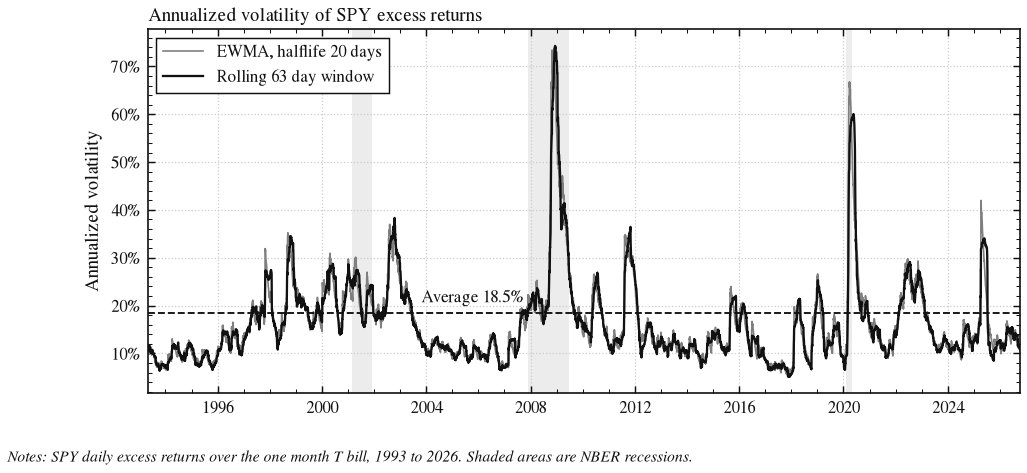

In [11]:
rolling = risk.rolling_vol(result["excess"], window=VOL_WINDOW, periods=ANN_FACTOR)
ewma = risk.ewma_vol(result["excess"], halflife=20, periods=ANN_FACTOR)
fig, ax = acad.new_fig("wide", aspect=0.42)
ax.plot(
    ewma, label="EWMA, halflife 20 days", color=acad.GREY, linestyle="-", linewidth=0.8
)
ax.plot(
    rolling, label=f"Rolling {VOL_WINDOW} day window", color=acad.INK, linestyle="-"
)
acad.recession_bands(ax)
plotting.reference_line(ax, summary["ann_vol"], "", axis="y")
ax.annotate(
    f"Average {summary['ann_vol']:.1%}",
    xy=(pd.Timestamp("2003-11-01"), summary["ann_vol"]),
    xytext=(0, 3),
    textcoords="offset points",
    va="bottom",
    fontsize=matplotlib.rcParams["legend.fontsize"],
)
acad.pct_axis(ax)
ax.set_ylabel("Annualized volatility")
ax.set_xlim(rolling.dropna().index[0], rolling.index[-1])
ax.set_title("Annualized volatility of SPY excess returns")
ax.legend(loc="upper left")
acad.source_note(
    fig,
    "Notes: SPY daily excess returns over the one month T bill, 1993 to 2026. Shaded areas are NBER recessions.",
)
acad.save(fig, "f0b_spy_volatility", outdir=OUTPUT_DIR)
plt.show()

**Figure 2.** SPY volatility ranged from 5% to 74% a year around its average of 18.5%.

**Reading the chart.** Calm years like 2017 sit near 5% a year, while late 2008 reached over 70%. Long quiet periods followed by short violent ones are exactly what produces the high kurtosis in Section 4.1. The EWMA line reacts faster than the 3 month window, which is why it is preferred for sizing positions.

## 5. Conclusions

1. **The engine passes the Phase 1 check.** SPY buy and hold since 1993 shows 18.5% volatility a year and a 55.2% maximum drawdown in 2007 to 2009, in line with the expected 19% and 55%.
2. **The lag works as intended.** A weight set at Monday's close earns Tuesday's return, and costs only arise when the position changes.
3. **The return distribution is not normal.** Kurtosis near 15 and volatility between 5% and 74% a year mean that Sharpe ratio estimates are noisier than the textbook formula suggests. Phase 2 builds the referee that corrects for this.

> **Caveats:** the risk free rate is rounded to 0.01% a day and carried forward for the last 28 days. Adjusted closes from Yahoo are revised when dividends are paid, so a fresh download can shift old returns very slightly; the cache keeps this notebook reproducible.

**Next step:** Phase 2, the referee (`quantlab.validation`) and the Monte Carlo notebook showing why the best of N backtests overstates its true quality.

## 6. Appendix: environment

In [12]:
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "quantlab": version("quantlab"),
}
print(", ".join(f"{k} {v}" for k, v in versions.items()))

python 3.12.11, numpy 2.5.4, pandas 3.0.6, matplotlib 3.11.2, quantlab 0.1.0
